# RGM Rollouts from Distill Prior Checkpoint

Rolls out using the RGM (Residual Gating Module) from a `distill_prior` checkpoint.
The RGM maps proprioception to a latent distribution `(mean, logvar)`, which is then
decoded to motor commands.

Options:
- Choose a fixed logvar for sampling, or use the RGM's predicted logvar
- 2D trajectory plots (all rollouts)
- Net distance plot (mean, min, max over time)
- Render selected trajectories to video

## Imports and Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import time
from typing import Tuple

import jax
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
import imageio
import mediapy as media
import mujoco
from mujoco import mjx
from ml_collections import config_dict

from scamper.agent.task_transfer.arena_forage.checkpoint_utils import (
    load_distill_prior_checkpoint,
    make_decoder_inference_fn,
    make_rgm_inference_fn,
)
from scamper.agent.mlp_prior.prior_networks import Prior
from brax.training.acme import running_statistics
from brax.training import distribution
from scamper.environment.rodent import arena_forage, consts

## Configuration

In [27]:
# ============ CHECKPOINT ============
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481"
CHECKPOINT_STEP = 54  # None = latest

# ============ ROLLOUT SETTINGS ============
NUM_ROLLOUTS = 20       # Total number of rollouts to run
MAX_STEPS = 1000         # Steps per rollout
NUM_RENDER = 5          # Number of rollouts to render to video

# ============ RGM SAMPLING ============
# If USE_PREDICTED_LOGVAR is True, sample using the RGM's own predicted logvar.
# Otherwise, use FIXED_LOGVAR for sampling (set very negative for near-deterministic).
USE_PREDICTED_LOGVAR = True
FIXED_LOGVAR = -2.0

# ============ RENDERING ============
RENDER_FPS = 50
CAMERA_NAME = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640

# ============ MISC ============
SEED = 42
XML_VARIANT = "limited-collisions"  # 'limited-collisions', 'full-collisions', 'no-tail-collisions'

## Load Checkpoint

In [28]:
(
    encoder_params,
    prior_params,
    decoder_params,
    rgm_params,
    normalizer_params,
    ckpt_cfg,
) = load_distill_prior_checkpoint(CHECKPOINT_PATH, step=CHECKPOINT_STEP)

latent_size = ckpt_cfg["network_config"]["intention_size"]
action_size = ckpt_cfg["network_config"]["action_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]

print(f"Latent size: {latent_size}")
print(f"Action size: {action_size}")
print(f"Proprio size: {proprio_size}")

Latent size: 16
Action size: 38
Proprio size: 277


## Build Inference Functions

In [29]:
# Decoder: [latent, proprio] -> action (deterministic mode from distribution)
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# RGM: proprio -> (mean, logvar)
rgm_fn = make_rgm_inference_fn(rgm_params, normalizer_params, ckpt_cfg)

print("Built decoder and RGM inference functions.")

Built decoder and RGM inference functions.


## Create Environment

In [30]:
env_cfg = arena_forage.default_config()

if XML_VARIANT == "limited-collisions":
    env_cfg.walker_xml_path = consts.RODENT_XML_PATH
elif XML_VARIANT == "full-collisions":
    env_cfg.walker_xml_path = consts.RODENT_FULL_COLLISION_XML
elif XML_VARIANT == "no-tail-collisions":
    env_cfg.walker_xml_path = consts.RODENT_NO_TAIL_COLLISION_XML

env_cfg.mujoco_impl = "jax"
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.torque_actuators = True

env = arena_forage.ArenaForage(config=env_cfg)
env._mjx_model = mjx.put_model(env._mj_model, impl=env_cfg.mujoco_impl)

print(f"Environment created (ctrl_dt={env_cfg.ctrl_dt})")
print(f"Action size: {env.action_size}")

Environment created (ctrl_dt=0.01)
Action size: 38


## Create RGM Policy

This policy takes raw proprioception, feeds it through the RGM to get a latent,
then decodes to a motor command. No gate, no prior, no residual — pure RGM.

In [31]:
def make_rgm_policy(rgm_fn, decoder_fn, latent_size, use_predicted_logvar, fixed_logvar):
    """Create a policy that uses only the RGM + decoder.

    Args:
        rgm_fn: (proprio) -> (mean, logvar)
        decoder_fn: (latent_proprio) -> (action, extras)
        latent_size: Latent dimension.
        use_predicted_logvar: If True, sample with RGM's predicted logvar.
        fixed_logvar: Fixed logvar for sampling (ignored if use_predicted_logvar).

    Returns:
        policy_fn: (proprio, rng) -> (action, extras)
    """

    def policy_fn(proprio, rng_key):
        rgm_mean, rgm_logvar = rgm_fn(proprio)

        if use_predicted_logvar:
            logvar = rgm_logvar
        else:
            logvar = jnp.full_like(rgm_mean, fixed_logvar)

        std = jnp.exp(0.5 * logvar)
        eps = jax.random.normal(rng_key, shape=rgm_mean.shape)
        z = rgm_mean + eps * std

        latent_proprio = jnp.concatenate([z, proprio], axis=-1)
        action, decoder_extras = decoder_fn(latent_proprio)

        extras = {
            "rgm_mean": rgm_mean,
            "rgm_logvar": rgm_logvar,
            "latent": z,
        }
        return action, extras

    return policy_fn


rgm_policy = make_rgm_policy(
    rgm_fn, decoder_fn, latent_size, USE_PREDICTED_LOGVAR, FIXED_LOGVAR
)

mode_str = "predicted logvar" if USE_PREDICTED_LOGVAR else f"fixed logvar={FIXED_LOGVAR}"
print(f"RGM policy created ({mode_str})")

RGM policy created (predicted logvar)


## Create Neutral Starting State

In [20]:
def create_neutral_state(env, rng_key):
    """Reset env and replace physics with neutral pose (qpos0, zero velocity)."""
    state = env.reset(rng_key)

    neutral_qpos = jnp.array(env.mj_model.qpos0)
    neutral_qpos = neutral_qpos.at[2].set(0)

    data = state.data.replace(qpos=neutral_qpos)
    data = data.replace(qvel=jnp.zeros(env.mjx_model.nv))
    data = mjx.forward(env.mjx_model, data)

    state = state.replace(data=data)
    return state


rng_init = jax.random.PRNGKey(SEED)
starting_state = create_neutral_state(env, rng_init)
print(f"Neutral state created. Root pos: {np.array(starting_state.data.qpos[:3])}")

KeyboardInterrupt: 

""

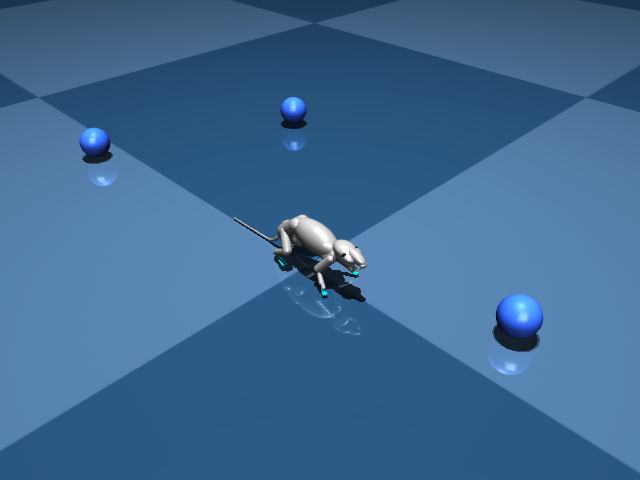

In [ ]:
# Preview starting pose
starting_frames = env.render(
    [starting_state], camera=CAMERA_NAME, height=RENDER_HEIGHT, width=RENDER_WIDTH,
    render_scent=False,
)
media.show_image(starting_frames[0])

## Run Rollouts

In [32]:
from scamper.agent.task_transfer.arena_forage.observation_utils import flatten_obs_dict
from scamper.agent.mlp_prior.prior_rollout_eval import (
    check_termination_nan,
    compute_world_zaxis_termination,
)


def create_vmapped_rollout(env, policy_fn, max_steps, proprio_size, starting_state):
    """Build a jit+vmap rollout function."""
    jit_step = jax.jit(env.step)

    def single_rollout(rng_key):
        state = starting_state

        def step_fn(carry, _):
            state, key, nan_term = carry
            key, key_action = random.split(key)

            # Extract raw proprioception
            if isinstance(state.obs, dict):
                flat_obs = flatten_obs_dict(state.obs)
                proprio = flat_obs["proprioception"]
            else:
                proprio = state.obs[..., -proprio_size:]

            action, _ = policy_fn(proprio, key_action)
            next_state = jit_step(state, action)

            step_nan = check_termination_nan(next_state.data)
            new_nan_term = jnp.logical_or(nan_term, step_nan)

            return (next_state, key, new_nan_term), next_state

        initial_carry = (state, rng_key, jnp.array(False))
        (_, _, nan_terminated), all_states = jax.lax.scan(
            step_fn, initial_carry, None, length=max_steps
        )

        upside_down = compute_world_zaxis_termination(env, all_states.data)
        any_upside_down = jnp.any(upside_down)
        first_upside_down = jnp.argmax(upside_down)

        terminated = jnp.logical_or(nan_terminated, any_upside_down)
        step_count = jnp.where(any_upside_down, first_upside_down + 1, max_steps)

        return step_count, terminated, all_states

    return jax.jit(jax.vmap(single_rollout))


vmapped_rollout = create_vmapped_rollout(
    env, rgm_policy, MAX_STEPS, proprio_size, starting_state
)
print(f"Compiled rollout function for {NUM_ROLLOUTS} x {MAX_STEPS} steps.")

Compiled rollout function for 20 x 1000 steps.


In [33]:
rng = random.PRNGKey(SEED)
rollout_keys = random.split(rng, NUM_ROLLOUTS)

print("Running rollouts (first run includes compilation)...")
t0 = time.time()
step_counts, terminated_flags, all_states = vmapped_rollout(rollout_keys)
step_counts = jnp.array(step_counts)
step_counts.block_until_ready()
elapsed = time.time() - t0

print(f"Done in {elapsed:.1f}s")
print(f"Step counts: {np.array(step_counts)}")
print(f"Terminated: {np.array(terminated_flags)}")
print(f"Avg steps: {float(jnp.mean(step_counts)):.0f}, "
      f"min: {int(jnp.min(step_counts))}, max: {int(jnp.max(step_counts))}")

Running rollouts (first run includes compilation)...
Done in 180.6s
Step counts: [1000  248  194 1000  678  324  324 1000  281 1000 1000 1000  149  956
 1000 1000 1000 1000  427 1000]
Terminated: [False  True  True False  True  True  True False  True False False False
  True  True False False False False  True False]
Avg steps: 729, min: 149, max: 1000


## Extract XY Trajectories

In [34]:
# all_states.data.qpos has shape (num_rollouts, max_steps, nq)
# Extract x,y for all rollouts
xy = np.array(all_states.data.qpos[:, :, :2])  # (num_rollouts, max_steps, 2)

# Origin-center each trajectory
xy_centered = xy - xy[:, 0:1, :]

# Net distance from start at each timestep
net_dist = np.sqrt(xy_centered[:, :, 0] ** 2 + xy_centered[:, :, 1] ** 2)  # (num_rollouts, max_steps)

print(f"XY shape: {xy.shape}")
print(f"Net distance shape: {net_dist.shape}")

XY shape: (20, 1000, 2)
Net distance shape: (20, 1000)


## 2D Trajectory Plots

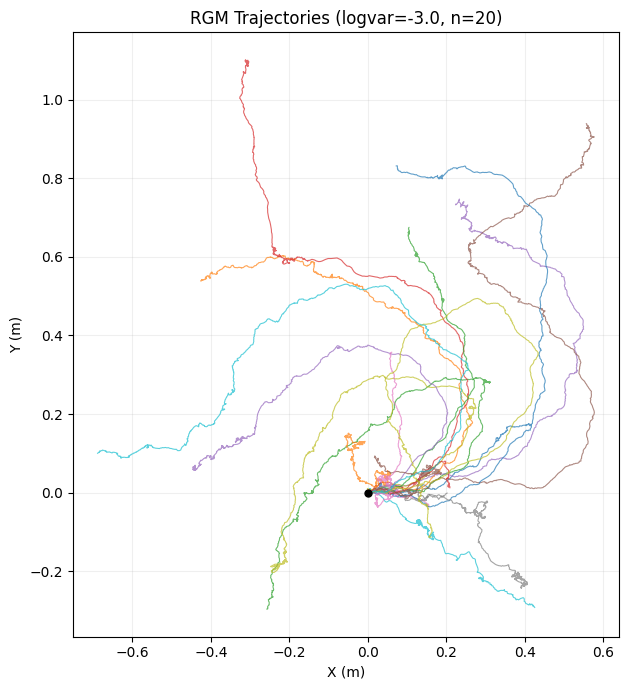

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))

for i in range(NUM_ROLLOUTS):
    n = int(step_counts[i])
    ax.plot(xy_centered[i, :n, 0], xy_centered[i, :n, 1], alpha=0.7, linewidth=0.8)

ax.plot(0, 0, "ko", markersize=5, zorder=5)
ax.set_aspect("equal")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
mode_label = "predicted logvar" if USE_PREDICTED_LOGVAR else f"logvar={FIXED_LOGVAR}"
ax.set_title(f"RGM Trajectories ({mode_label}, n={NUM_ROLLOUTS})")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

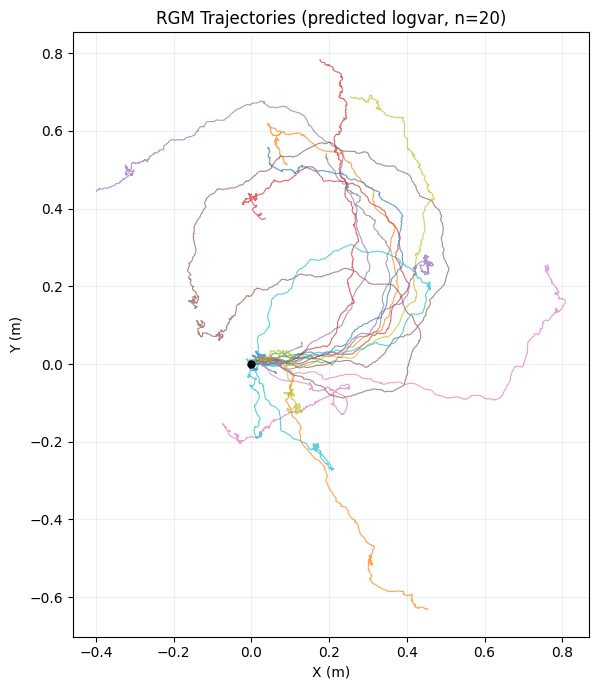

In [25]:
fig, ax = plt.subplots(figsize=(7, 7))

for i in range(NUM_ROLLOUTS):
    n = int(step_counts[i])
    ax.plot(xy_centered[i, :n, 0], xy_centered[i, :n, 1], alpha=0.7, linewidth=0.8)

ax.plot(0, 0, "ko", markersize=5, zorder=5)
ax.set_aspect("equal")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
mode_label = "predicted logvar" if USE_PREDICTED_LOGVAR else f"logvar={FIXED_LOGVAR}"
ax.set_title(f"RGM Trajectories ({mode_label}, n={NUM_ROLLOUTS})")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

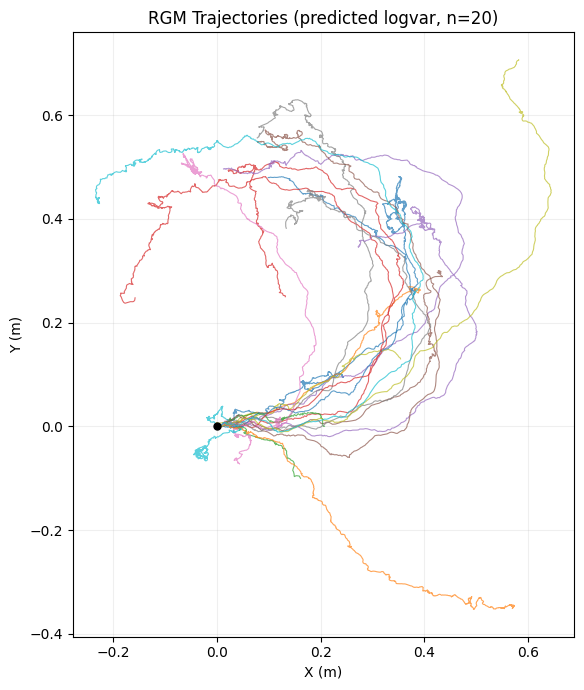

In [35]:
fig, ax = plt.subplots(figsize=(7, 7))

for i in range(NUM_ROLLOUTS):
    n = int(step_counts[i])
    ax.plot(xy_centered[i, :n, 0], xy_centered[i, :n, 1], alpha=0.7, linewidth=0.8)

ax.plot(0, 0, "ko", markersize=5, zorder=5)
ax.set_aspect("equal")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
mode_label = "predicted logvar" if USE_PREDICTED_LOGVAR else f"logvar={FIXED_LOGVAR}"
ax.set_title(f"RGM Trajectories ({mode_label}, n={NUM_ROLLOUTS})")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## Net Distance Plot (Mean, Min, Max)

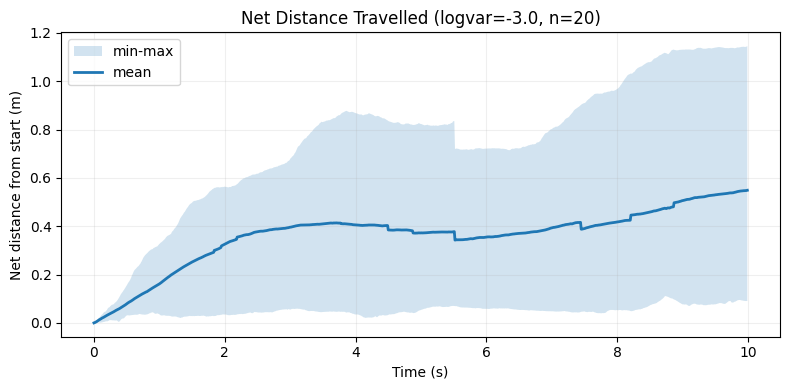

In [14]:
# Build a mask for valid steps per rollout
step_indices = np.arange(MAX_STEPS)[None, :]  # (1, max_steps)
valid_mask = step_indices < np.array(step_counts)[:, None]  # (num_rollouts, max_steps)

# Mask out post-termination distances with NaN for proper min/max/mean
net_dist_masked = np.where(valid_mask, net_dist, np.nan)

mean_dist = np.nanmean(net_dist_masked, axis=0)
min_dist = np.nanmin(net_dist_masked, axis=0)
max_dist = np.nanmax(net_dist_masked, axis=0)

# Only plot up to the step where at least one rollout is still alive
alive_count = np.sum(valid_mask, axis=0)
last_alive = int(np.max(np.where(alive_count > 0)[0])) + 1 if np.any(alive_count > 0) else MAX_STEPS

timesteps = np.arange(last_alive)
dt = float(env_cfg.ctrl_dt)
time_s = timesteps * dt

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(time_s, min_dist[:last_alive], max_dist[:last_alive], alpha=0.2, label="min-max")
ax.plot(time_s, mean_dist[:last_alive], linewidth=2, label="mean")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Net distance from start (m)")
ax.set_title(f"Net Distance Travelled ({mode_label}, n={NUM_ROLLOUTS})")
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

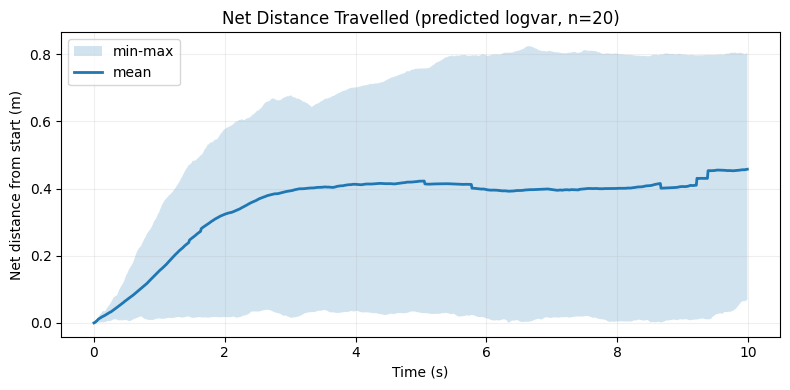

In [26]:
# Build a mask for valid steps per rollout
step_indices = np.arange(MAX_STEPS)[None, :]  # (1, max_steps)
valid_mask = step_indices < np.array(step_counts)[:, None]  # (num_rollouts, max_steps)

# Mask out post-termination distances with NaN for proper min/max/mean
net_dist_masked = np.where(valid_mask, net_dist, np.nan)

mean_dist = np.nanmean(net_dist_masked, axis=0)
min_dist = np.nanmin(net_dist_masked, axis=0)
max_dist = np.nanmax(net_dist_masked, axis=0)

# Only plot up to the step where at least one rollout is still alive
alive_count = np.sum(valid_mask, axis=0)
last_alive = int(np.max(np.where(alive_count > 0)[0])) + 1 if np.any(alive_count > 0) else MAX_STEPS

timesteps = np.arange(last_alive)
dt = float(env_cfg.ctrl_dt)
time_s = timesteps * dt

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(time_s, min_dist[:last_alive], max_dist[:last_alive], alpha=0.2, label="min-max")
ax.plot(time_s, mean_dist[:last_alive], linewidth=2, label="mean")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Net distance from start (m)")
ax.set_title(f"Net Distance Travelled ({mode_label}, n={NUM_ROLLOUTS})")
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## Render Selected Rollouts

In [ ]:
def render_rollout_from_stacked(env, stacked_states, num_steps, camera, height, width):
    """Render one rollout from vmapped stacked states."""
    states_list = []
    for t in range(num_steps):
        state_t = jax.tree_util.tree_map(lambda x: x[t], stacked_states)
        states_list.append(state_t)
    return env.render(
        states_list, camera=camera, height=height, width=width, render_scent=False
    )


# Pick which rollouts to render (first NUM_RENDER, or override indices here)
render_indices = list(range(min(NUM_RENDER, NUM_ROLLOUTS)))
print(f"Rendering rollouts: {render_indices}")

rendered_videos = []
for idx in render_indices:
    rollout_states_i = jax.tree_util.tree_map(lambda x: x[idx], all_states)
    n = int(step_counts[idx])
    print(f"  Rollout {idx}: rendering {n} steps...")
    frames = render_rollout_from_stacked(
        env, rollout_states_i, n, CAMERA_NAME, RENDER_HEIGHT, RENDER_WIDTH
    )
    rendered_videos.append(frames)

print("Rendering done.")

In [ ]:
for i, (idx, frames) in enumerate(zip(render_indices, rendered_videos)):
    n = int(step_counts[idx])
    print(f"Rollout {idx} ({n} steps):")
    media.show_video(frames, fps=RENDER_FPS)

## Summary

In [ ]:
sc = np.array(step_counts)
nd_final = np.array([net_dist[i, int(sc[i]) - 1] if sc[i] > 0 else 0.0 for i in range(NUM_ROLLOUTS)])

print("=" * 50)
print("RGM ROLLOUT SUMMARY")
print("=" * 50)
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Step: {CHECKPOINT_STEP}")
print(f"Sampling: {'predicted logvar' if USE_PREDICTED_LOGVAR else f'fixed logvar={FIXED_LOGVAR}'}")
print(f"Rollouts: {NUM_ROLLOUTS}, max steps: {MAX_STEPS}")
print()
print(f"Steps  — mean: {np.mean(sc):.0f}, min: {np.min(sc)}, max: {np.max(sc)}")
print(f"Term rate: {np.mean(np.array(terminated_flags)):.0%}")
print(f"Final net dist (m) — mean: {np.mean(nd_final):.3f}, "
      f"min: {np.min(nd_final):.3f}, max: {np.max(nd_final):.3f}")
print("=" * 50)